# 01 · GAN basics: a digit forger on MNIST
### The Class 1 notebook (CV-Week4-Lecture1.ipynb), rebuilt, explained line by line, and all four in-class tasks done for real

**Covers (GAN Class 1 slides):** what GAN stands for · Generator and Discriminator · binary cross-entropy · the training loop (D step, then G step) · the minimax objective and the 1.386 / 0.693 reference numbers · the non-saturating generator loss · Tasks 1–4 and the exit ticket.

**Where the code comes from.** The course notebook itself was not handed out, but the course guide *"GAN Class 1 Notebook Explained"* (in `course-files/`) quotes every line of its GAN cell. The code below is that code, with the **same class names, layer sizes and variable names** (`optimizer_g`, `optimizer_d`, `labels_real`, `labels_fake`, `loss_d`, `loss_g`, `fake.detach()` ...), so you will recognise it in the exam. Lines marked `# (added)` are extras for this notebook (seeds, timing, record keeping); they do not change what the GAN does.

Run each cell with **Shift + Enter** and read the text around it. The whole notebook runs on a laptop CPU in a few minutes.

> **The story (from the slides).** A **forger** (the Generator, G) paints fake pictures but is never allowed to look at real ones. An **inspector** (the Discriminator, D) is shown real pictures and the forger's fakes and must say how likely each one is to be real. The forger learns *only* from the inspector's reactions. Round after round both improve, until the inspector can only guess: it says **0.5** for everything.

## 0 · Setup
Install once from a terminal: `pip install torch torchvision matplotlib`. On Google Colab everything is already installed. No GPU is needed.

In [1]:
%matplotlib inline
import time
import math
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torchvision.utils import make_grid
from torch.utils.data import DataLoader

torch.manual_seed(0)          # (added) same random numbers every run, so your output matches the text
np.random.seed(0)
plt.rcParams["figure.dpi"] = 80
print("torch", torch.__version__, "| GPU available:", torch.cuda.is_available())

torch 2.14.1+cu130 | GPU available: False


### Words you need first

| Term | Plain meaning | In the code |
|---|---|---|
| **Generator (G)** | network that turns random numbers into an image (the forger) | `Generator` class |
| **Discriminator (D)** | network that takes an image and outputs P(real), a number from 0 to 1 (the inspector) | `Discriminator` class |
| **Noise vector z** | a list of 100 random numbers fed to G; a different z gives a different image | `torch.randn(batch_size, 100)` |
| **Real image x** | an image from the dataset | `real` |
| **Fake image G(z)** | an image made by the generator | `fake` |
| **Label / target** | the answer we want D to give: 1 = real, 0 = fake | `labels_real`, `labels_fake` |
| **BCE** | binary cross-entropy: loss for yes/no predictions | `nn.BCELoss()` |
| **Batch / epoch** | 64 images at a time / one pass over all 60,000 images | `batch_size=64`, `epochs = 2` |
| **Optimizer** | updates a network's weights using gradients | `optim.Adam(...)` |

If you know how a classifier is trained (forward pass → loss → `backward()` → `optimizer.step()`), you already know every building block. **A GAN simply trains two networks in turns, against each other.**

In the course notebook the whole GAN is **one code cell** (cell 5). Here it is split into small cells so each part can be explained, in exactly the same order: data → Generator → Discriminator → loss and optimizers → training loop → plot 16 samples.

## 1 · The data: MNIST

In [2]:
# Dataset  (course code)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])
train_data = datasets.MNIST(root='./data', train=True, transform=transform, download=True)
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)

print("training images:", len(train_data))
print("batches per epoch:", len(train_loader), "(937 full batches of 64 + one of", len(train_data) - 937 * 64, ")")

training images: 60000
batches per epoch: 938 (937 full batches of 64 + one of 32 )


- **MNIST** = 60,000 training images of handwritten digits 0–9, each **28 × 28 = 784** grey pixels. `download=True` fetches it into `./data` the first time (about 10 MB).
- **`ToTensor()`** turns each image into a tensor of shape **(1, 28, 28)** with values 0 (black) to 1 (white).
- **`Normalize((0.5,), (0.5,))`** computes (pixel − 0.5) / 0.5, so **0 → −1 and 1 → +1**. Remember this range: the Generator must produce the same range.
- **`batch_size=64`, `shuffle=True`**: the loop receives 64 images at a time, in a new random order every epoch.
- The dataset also has the digit labels, but **this GAN never uses them**. It learns what digits look like in general, not which one is which.

Let's check the slide's example: *pixel 204 → 0.8 → +0.6, pixel 0 → 0.0 → −1.0*, and look at one batch.

stored pixel   0 -> ToTensor 0.00 -> Normalize -1.00
stored pixel 204 -> ToTensor 0.80 -> Normalize +0.60
stored pixel 255 -> ToTensor 1.00 -> Normalize +1.00

one batch: (64, 1, 28, 28) | min -1.0 | max 1.0


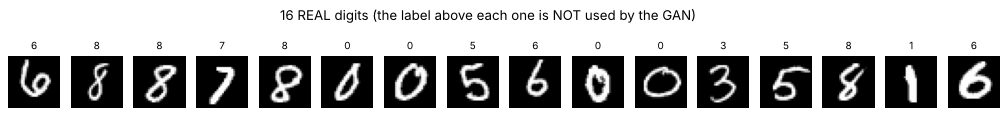

In [3]:
for raw in [0, 204, 255]:
    v = raw / 255                      # what ToTensor does
    print(f"stored pixel {raw:3d} -> ToTensor {v:.2f} -> Normalize {(v - 0.5) / 0.5:+.2f}")

real, labels = next(iter(train_loader))
print("\none batch:", tuple(real.shape), "| min", real.min().item(), "| max", real.max().item())
fig, axes = plt.subplots(1, 16, figsize=(16, 1.6))
for i in range(16):
    axes[i].imshow(real[i][0], cmap='gray'); axes[i].set_title(int(labels[i]), fontsize=9); axes[i].axis('off')
plt.suptitle("16 REAL digits (the label above each one is NOT used by the GAN)", y=1.08)
plt.show()

## 2 · The Generator: the forger

In [4]:
class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(100, 256),     # 100 noise numbers -> 256 hidden values
            nn.ReLU(),               # keep positives, set negatives to 0
            nn.Linear(256, 784),     # 256 -> 784 = one value per pixel (28 x 28)
            nn.Tanh()                # squash every value into -1 ... +1, like the real images
        )

    def forward(self, x):
        return self.fc(x).view(-1, 1, 28, 28)   # 784 numbers -> an image (batch, 1 channel, 28, 28)

| Line | What it does | Why |
|---|---|---|
| `nn.Linear(100, 256)` | mixes the 100 noise values into 256 hidden values | 100 must match `torch.randn(..., 100)` in the loop |
| `nn.ReLU()` | keeps positives, sets negatives to 0 | non-linearity, so G can draw curved shapes |
| `nn.Linear(256, 784)` | produces 784 values | one per pixel: 28 × 28 = 784 |
| `nn.Tanh()` | squashes each value into −1 … +1 | **same range as the real images** after `Normalize`. Otherwise D could catch fakes just by their range, which teaches G nothing |
| `.view(-1, 1, 28, 28)` | reshapes 784 numbers into an image | 1 grey channel, 28 × 28; `-1` = "whatever the batch size is" |

**Where does variety come from?** G is a fixed function: the same 100 numbers always give the same image. New images come from **new noise**. Before training, the weights are random, so the output is static. Let's see that.

input z: (4, 100) -> output: (4, 1, 28, 28) | values between -0.66 and 0.72
parameters in G: 227344


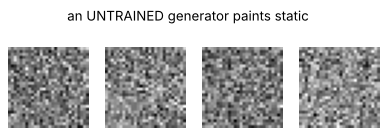

In [5]:
g_untrained = Generator()
z = torch.randn(4, 100)                       # 4 noise vectors of 100 numbers each
out = g_untrained(z)
print("input z:", tuple(z.shape), "-> output:", tuple(out.shape), "| values between", round(out.min().item(), 2), "and", round(out.max().item(), 2))
print("parameters in G:", sum(p.numel() for p in g_untrained.parameters()))
fig, axes = plt.subplots(1, 4, figsize=(6, 1.8))
for i in range(4):
    axes[i].imshow(out[i][0].detach(), cmap='gray'); axes[i].axis('off')
plt.suptitle("an UNTRAINED generator paints static", y=1.05); plt.show()

## 3 · The Discriminator: the inspector

In [6]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(784, 256),     # 784 pixels -> 256 hidden values (strokes, loops ...)
            nn.LeakyReLU(0.2),       # negatives are multiplied by 0.2 instead of zeroed
            nn.Linear(256, 1),       # 256 -> one score
            nn.Sigmoid()             # score -> probability 0 ... 1 = P(real)
        )

    def forward(self, x):
        return self.fc(x.view(-1, 784))   # flatten each 1x28x28 image into 784 numbers first

| Line | What it does | Why |
|---|---|---|
| `x.view(-1, 784)` | flattens each image into 784 numbers | `Linear` layers need a flat list |
| `nn.Linear(784, 256)` | 784 pixels → 256 hidden values | learns patterns such as strokes and loops |
| `nn.LeakyReLU(0.2)` | keeps positives; multiplies negatives by 0.2 | a small gradient **always** flows back. G learns *only* through gradients passing back through D, so D must not block them (plain ReLU gives zero gradient for negatives) |
| `nn.Linear(256, 1)` | one score | one decision: real or fake |
| `nn.Sigmoid()` | squashes the score into 0 … 1 | read it as a probability; needed for `nn.BCELoss` |

The two networks are **mirror images**: G is 100 → 256 → 784, D is 784 → 256 → 1.

**Where do D's labels come from?** For free: we know which pile each image came from. Images from MNIST get target 1, images just made by G get target 0. The target describes the **source**, not the quality; a perfect-looking fake is still target 0 when D is trained.

In [7]:
d_untrained = Discriminator()
p = d_untrained(real[:4])                       # 4 real digits from the batch above
print("input:", tuple(real[:4].shape), "-> output:", tuple(p.shape))
print("untrained D's P(real) for 4 real digits:", p.detach().view(-1).numpy().round(3), " (about 0.5: it has no opinion yet)")

input: (4, 1, 28, 28) -> output: (4, 1)
untrained D's P(real) for 4 real digits: [0.445 0.444 0.442 0.382]  (about 0.5: it has no opinion yet)


## 4 · One loss, two optimizers

### Binary cross-entropy, with the slide's numbers computed in code

  **BCE(p, y) = −[ y·log p + (1 − y)·log(1 − p) ]**  (natural log)

Only one half is active at a time: target **y = 1 → loss = −log p**; target **y = 0 → loss = −log(1 − p)**. Small when confident and right, large when confident and wrong. Let's reproduce the table from the "THE LOSS: NN.BCELOSS" slide with `nn.BCELoss` itself.

In [8]:
criterion = nn.BCELoss()
cases = [("D, real digit, confident", 1, 0.9),
         ("D, real digit, wrong",     1, 0.1),
         ("D, fake digit, confident", 0, 0.2),
         ("G, same fake (wants y=1)", 1, 0.2)]
print(f"{'case':28s} {'y':>2s} {'p':>5s} {'BCE':>7s}")
for name, y, p in cases:
    loss = criterion(torch.tensor([p]), torch.tensor([float(y)]))
    print(f"{name:28s} {y:2d} {p:5.1f} {loss.item():7.3f}")

print("\nD's loss for one real (0.9) + one fake (0.2):", round(-math.log(0.9) - math.log(1 - 0.2), 3), "(low: D is doing well)")
print("G's loss on that same fake:  -ln 0.2 =", round(-math.log(0.2), 3), "(high: G must improve)")
print("\nReference numbers when D says 0.5 for everything:")
print("  loss_d = -ln 0.5 - ln 0.5 =", round(2 * math.log(2), 3), "   loss_g = -ln 0.5 =", round(math.log(2), 3))

case                          y     p     BCE
D, real digit, confident      1   0.9   0.105
D, real digit, wrong          1   0.1   2.303
D, fake digit, confident      0   0.2   0.223
G, same fake (wants y=1)      1   0.2   1.609

D's loss for one real (0.9) + one fake (0.2): 0.329 (low: D is doing well)
G's loss on that same fake:  -ln 0.2 = 1.609 (high: G must improve)

Reference numbers when D says 0.5 for everything:
  loss_d = -ln 0.5 - ln 0.5 = 1.386    loss_g = -ln 0.5 = 0.693


The last two rows of the table are **"adversarial" in numbers**: the same fake and the same score 0.2 are **good news for D (0.223)** and **bad news for G (1.609)**.

The slides also walk through **one round of the game** with illustrative scores. Here are those losses computed:

In [9]:
def bce_pair(dx, dgz):
    loss_d = -math.log(dx) - math.log(1 - dgz)     # real -> 1, fake -> 0
    loss_g = -math.log(dgz)                        # fake -> 1 (G's wish)
    return loss_d, loss_g

print(f"{'moment':16s} {'D(x)':>5s} {'D(G(z))':>8s} {'D loss':>7s} {'G loss':>7s}")
for moment, dx, dgz in [("start of round", 0.60, 0.40), ("after D step", 0.70, 0.30), ("after G step", 0.70, 0.45)]:
    ld, lg = bce_pair(dx, dgz)
    print(f"{moment:16s} {dx:5.2f} {dgz:8.2f} {ld:7.3f} {lg:7.3f}")

moment            D(x)  D(G(z))  D loss  G loss
start of round    0.60     0.40   1.022   0.916
after D step      0.70     0.30   0.713   1.204
after G step      0.70     0.45   0.955   0.799


The D step lowers D's loss (1.022 → 0.713) and, as a side effect, raises G's (0.916 → 1.204). The G step lowers G's loss (→ 0.799) and raises D's again. **Neither wins for good**, which is why GAN losses wobble instead of falling steadily.

### The course code: create the players, the loss and two optimizers

In [10]:
torch.manual_seed(0)                      # (added) so this run is repeatable
generator = Generator()
discriminator = Discriminator()
criterion = nn.BCELoss()
optimizer_g = optim.Adam(generator.parameters(), lr=0.0002)
optimizer_d = optim.Adam(discriminator.parameters(), lr=0.0002)

**Two optimizers** are the trick that keeps the two steps separate: `optimizer_g` holds **only G's weights**, `optimizer_d` holds **only D's**. So `optimizer_d.step()` can change only D and `optimizer_g.step()` only G. Both use Adam with learning rate 0.0002 (a common GAN setting; Adam's other settings are left at the PyTorch default `betas=(0.9, 0.999)`, which matters in Task 3 D).

## 5 · The training loop: every batch = one round of the game

Step 1 trains the inspector, step 2 trains the forger. This is the course loop line for line. The only additions (marked) keep a record of the losses and of D's average opinions so we can compare runs later.

In [11]:
epochs = 2
history = []                                                   # (added) one row per epoch
t0 = time.time()                                               # (added)
for epoch in range(epochs):
    sum_d = sum_g = sum_dx = sum_dgz = 0.0; n = 0              # (added) running totals for epoch averages
    for real, _ in train_loader:
        real = real                                            # (in the course notebook; does nothing)
        batch_size = real.size(0)
        labels_real = torch.ones(batch_size, 1)
        labels_fake = torch.zeros(batch_size, 1)

        # Step 1: Train Discriminator
        optimizer_d.zero_grad()
        outputs_real = discriminator(real)
        loss_real = criterion(outputs_real, labels_real)
        noise = torch.randn(batch_size, 100)
        fake = generator(noise)
        outputs_fake = discriminator(fake.detach())
        loss_fake = criterion(outputs_fake, labels_fake)
        loss_d = loss_real + loss_fake
        loss_d.backward()
        optimizer_d.step()

        # Step 2: Train Generator
        optimizer_g.zero_grad()
        outputs_fake = discriminator(fake)
        loss_g = criterion(outputs_fake, labels_real)
        loss_g.backward()
        optimizer_g.step()

        sum_d += loss_d.item(); sum_g += loss_g.item(); n += 1                       # (added)
        sum_dx += outputs_real.mean().item(); sum_dgz += outputs_fake.mean().item()  # (added)
    print(f"Epoch {epoch+1}/{epochs}, Loss D: {loss_d.item()}, Loss G: {loss_g.item()}")
    history.append((loss_d.item(), loss_g.item(), sum_d / n, sum_g / n, sum_dx / n, sum_dgz / n))  # (added)
print(f"(added) training time: {time.time() - t0:.0f} s for {epochs} epochs x {len(train_loader)} batches")

Epoch 1/2, Loss D: 0.5900115966796875, Loss G: 1.403838038444519


Epoch 2/2, Loss D: 1.041710376739502, Loss G: 1.057669997215271
(added) training time: 172 s for 2 epochs x 938 batches


### What each part of the loop does

**Setting up each batch**
- `for real, _ in train_loader` takes 64 real digits; `_` throws the digit labels away.
- `batch_size = real.size(0)` reads the *actual* batch size: 64, except the last batch of each epoch, which has 32. (That is why the code does not just write 64.)
- `labels_real` is a column of 1s, `labels_fake` a column of 0s, one per image.

**Step 1: train the Discriminator (G stays fixed)**
- `optimizer_d.zero_grad()` clears old gradients.
- *Real exam:* D judges the real digits; `loss_real` = BCE against target 1, so D is punished for calling real digits fake.
- *Fake exam:* `torch.randn(batch_size, 100)` draws fresh noise, G turns it into fakes, D judges them; `loss_fake` = BCE against target 0.
- **`fake.detach()`** cuts the wire from these images back to G, so D's loss sends no gradient into G.
- `loss_d = loss_real + loss_fake` is D's total mistake; `backward()` + `optimizer_d.step()` update **only D**.

**Step 2: train the Generator (D is not updated)**
- The **same** fakes go through the *just-updated* D, this time **without** `.detach()`, so gradients flow back **through D into G**.
- **`loss_g = criterion(outputs_fake, labels_real)`**: target **1** for fake images. Not a lie about the data: it states G's goal, "my loss is low only when D believes my images are real".
- `optimizer_g.step()` changes **only G**. D's leftover gradients are cleared at the next `optimizer_d.zero_grad()`.

**The print line** sits outside the batch loop, so it shows the losses of the **last batch** of each epoch: noisy snapshots, not averages. One epoch = 938 batches = 938 rounds of the game; 2 epochs = 1,876 rounds.

## 6 · Making 16 new digits (course code)

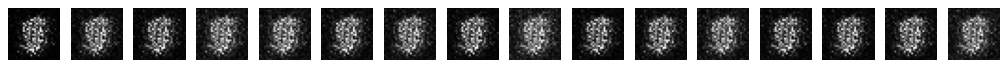

In [12]:
noise = torch.randn(16, 100)
fake_images = generator(noise).detach()
fig, axes = plt.subplots(1, 16, figsize=(16,2))
for i in range(16):
    axes[i].imshow(fake_images[i][0], cmap='gray')
    axes[i].axis('off')
plt.show()

This uses **only the Generator**: 16 new noise vectors in, 16 new digits out. `.detach()` says "no gradients needed, we are only looking". `fake_images[i][0]` picks image *i* and its only channel.

---
# In-class tasks (slides "TASK 1 OF 4" … "TASK 4 OF 4")

## Task 1 · Run the GAN and observe
> 1. Predict what the 16 digits will look like. 2. Write down Loss D and Loss G for each epoch and compare with **1.386 / 0.693**. 3. How many look like digits? How many different digits? 4. Re-run just the plotting lines: why do you get different digits?

In [13]:
print(f"{'epoch':>5s} | {'last-batch D':>12s} {'last-batch G':>12s} | {'epoch-avg D':>11s} {'epoch-avg G':>11s} | {'mean D(x)':>9s} {'mean D(G(z))':>12s}")
for e, (ld, lg, ad, ag, dx, dgz) in enumerate(history, 1):
    print(f"{e:5d} | {ld:12.3f} {lg:12.3f} | {ad:11.3f} {ag:11.3f} | {dx:9.3f} {dgz:12.3f}")
print(f"{'ref':>5s} | {1.386:12.3f} {0.693:12.3f} |  <- the values if D said 0.5 for everything")

epoch | last-batch D last-batch G | epoch-avg D epoch-avg G | mean D(x) mean D(G(z))
    1 |        0.590        1.404 |       0.700       1.369 |     0.811        0.298
    2 |        1.042        1.058 |       0.829       1.261 |     0.714        0.302
  ref |        1.386        0.693 |  <- the values if D said 0.5 for everything


(pending T1)

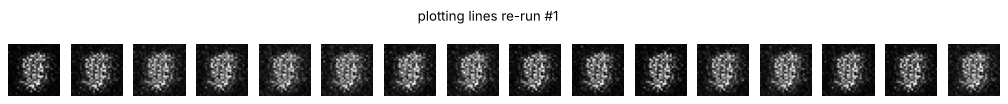

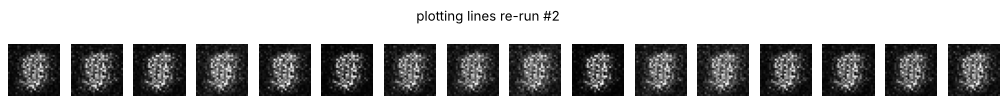

In [14]:
# 4. Run just the plotting lines again: new noise, same generator, no retraining
for run in range(2):
    noise = torch.randn(16, 100)
    fake_images = generator(noise).detach()
    fig, axes = plt.subplots(1, 16, figsize=(16, 1.4))
    for i in range(16):
        axes[i].imshow(fake_images[i][0], cmap='gray'); axes[i].axis('off')
    plt.suptitle(f"plotting lines re-run #{run + 1}", y=1.05); plt.show()

**Why different digits without retraining?** `torch.randn(16, 100)` draws **new noise** every time. G's weights did not change, but its input did, and G is a function: new input, new output. That is the Generator doing its job.

## Task 2 · Read the code like a GAN detective

| Question | Answer |
|---|---|
| **a.** Which line gives D its "fake" targets? What value? | `labels_fake = torch.zeros(batch_size, 1)`: all **0** |
| **b.** Why `.detach()` in the D step but not in the G step? | D step: we train only D, so we **stop** gradients flowing into G. G step: the gradient **must** travel through D back into G, so the path stays connected |
| **c.** Why does the G loss use `labels_real`? | G wants D(G(z)) → 1. Minimising BCE with target 1 = minimising −log D(G(z)): the **non-saturating** generator loss (next section shows why it is used) |
| **d.** Shape of `fake` in a full batch? | **(64, 1, 28, 28)**: 64 images, 1 channel, 28 × 28 |

Two of these can be checked in code:

In [15]:
noise = torch.randn(64, 100)
fake = generator(noise)
print("d. shape of fake in a full batch:", tuple(fake.shape))

# b. what .detach() does: does a loss on D's output reach G's weights?
generator.zero_grad()
criterion(discriminator(fake.detach()), torch.zeros(64, 1)).backward()
print("b. with    .detach(): G's first-layer gradient is", generator.fc[0].weight.grad)
criterion(discriminator(fake), torch.ones(64, 1)).backward()
print("b. without .detach(): G's first-layer gradient size =", round(generator.fc[0].weight.grad.abs().sum().item(), 3))
generator.zero_grad(); discriminator.zero_grad()      # tidy up: we are not training here

d. shape of fake in a full batch: (64, 1, 28, 28)
b. with    .detach(): G's first-layer gradient is None
b. without .detach(): G's first-layer gradient size = 97.59


With `.detach()` no gradient reaches G at all (`None`); without it, G receives a gradient. That is exactly how one loop trains two networks separately.

### Why `labels_real` for G? Saturating vs non-saturating loss
The minimax objective (Goodfellow et al., 2014) is

  **min over G, max over D of  E[log D(x)] + E[log(1 − D(G(z)))]**

so, read literally, G should **minimise log(1 − D(G(z)))** (the *saturating* loss). The code instead minimises **−log D(G(z))** (BCE with target 1, the *non-saturating* loss). Both push D(G(z)) towards 1. The difference is the **size of the push** early in training, when fakes are bad and D(G(z)) ≈ 0.

D's last layer is a Sigmoid: p = sigmoid(a), where *a* is D's raw score. The gradient that reaches G passes through *a*. A little calculus gives:
- saturating loss log(1 − p): gradient w.r.t. *a* is **−p**, which is ≈ 0 when p ≈ 0 (flat, "saturated");
- non-saturating loss −log p: gradient w.r.t. *a* is **−(1 − p)**, which is ≈ −1 when p ≈ 0 (steep).

We check this with autograd rather than trusting the algebra:

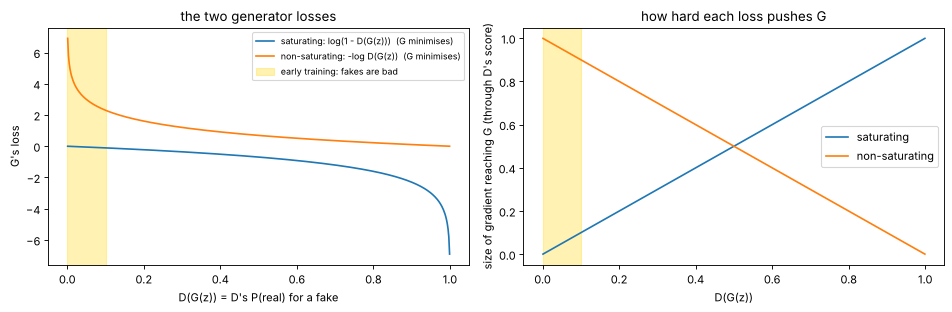

D(G(z)) = 0.001:  saturating push 0.001   non-saturating push 0.999
D(G(z)) = 0.009:  saturating push 0.009   non-saturating push 0.991
D(G(z)) = 0.099:  saturating push 0.099   non-saturating push 0.901
D(G(z)) = 0.499:  saturating push 0.499   non-saturating push 0.501
D(G(z)) = 0.899:  saturating push 0.899   non-saturating push 0.101


In [16]:
p = torch.linspace(0.001, 0.999, 500)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(p, torch.log(1 - p), label="saturating: log(1 - D(G(z)))  (G minimises)")
ax[0].plot(p, -torch.log(p), label="non-saturating: -log D(G(z))  (G minimises)")
ax[0].axvspan(0, 0.1, color="gold", alpha=0.3, label="early training: fakes are bad")
ax[0].set_xlabel("D(G(z)) = D's P(real) for a fake"); ax[0].set_ylabel("G's loss"); ax[0].legend(fontsize=8); ax[0].set_title("the two generator losses")

a = torch.logit(p).clone().requires_grad_(True)            # D's raw score before the Sigmoid
torch.log(1 - torch.sigmoid(a)).sum().backward(); g_sat = a.grad.clone(); a.grad = None
(-torch.log(torch.sigmoid(a))).sum().backward(); g_ns = a.grad.clone()
ax[1].plot(p, g_sat.abs(), label="saturating")
ax[1].plot(p, g_ns.abs(), label="non-saturating")
ax[1].axvspan(0, 0.1, color="gold", alpha=0.3)
ax[1].set_xlabel("D(G(z))"); ax[1].set_ylabel("size of gradient reaching G (through D's score)"); ax[1].legend(); ax[1].set_title("how hard each loss pushes G")
plt.tight_layout(); plt.show()

for pv in [0.001, 0.01, 0.1, 0.5, 0.9]:
    i = int(torch.argmin((p - pv).abs()))
    print(f"D(G(z)) = {p[i]:.3f}:  saturating push {g_sat[i].abs():.3f}   non-saturating push {g_ns[i].abs():.3f}")

When D(G(z)) is 0.001 (a terrible fake, the usual start), the saturating loss pushes G with strength about 0.001, the non-saturating loss with about 1: **roughly a thousand times stronger, exactly when G needs it**. Same goal, better gradients. The 2014 GAN paper itself suggests this trick, and `criterion(outputs_fake, labels_real)` is how the course code implements it.

Does it matter in practice? Let's train the same GAN for the same 2 epochs with the **saturating** loss (the only change: G minimises log(1 − D(G(z))) instead of BCE with `labels_real`), from the same seed.

saturating loss, epoch 1: mean D(G(z)) = 0.085


saturating loss, epoch 2: mean D(G(z)) = 0.018
(264 s)
course (non-saturating) run, mean D(G(z)) per epoch: [0.298, 0.302]


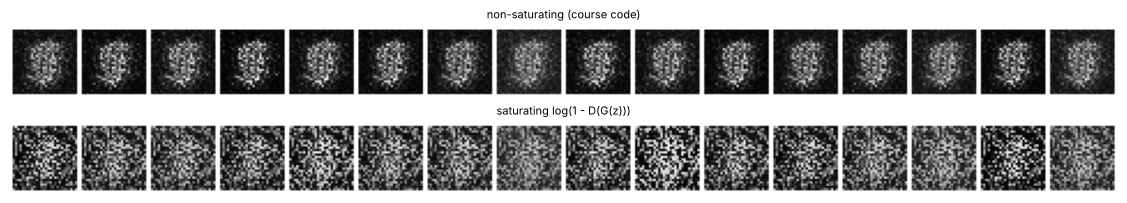

In [17]:
def train_saturating(epochs=2, seed=0):
    torch.manual_seed(seed)
    G, D = Generator(), Discriminator()
    opt_g = optim.Adam(G.parameters(), lr=0.0002); opt_d = optim.Adam(D.parameters(), lr=0.0002)
    for epoch in range(epochs):
        dgz_sum, n = 0.0, 0
        for real, _ in train_loader:
            b = real.size(0)
            opt_d.zero_grad()
            fake = G(torch.randn(b, 100))
            loss_d = criterion(D(real), torch.ones(b, 1)) + criterion(D(fake.detach()), torch.zeros(b, 1))
            loss_d.backward(); opt_d.step()
            opt_g.zero_grad()
            out = D(fake)
            loss_g = torch.log(1 - out + 1e-8).mean()     # <- the ONLY change: the saturating minimax loss
            loss_g.backward(); opt_g.step()
            dgz_sum += out.mean().item(); n += 1
        print(f"saturating loss, epoch {epoch+1}: mean D(G(z)) = {dgz_sum / n:.3f}")
    return G

t0 = time.time()
G_sat = train_saturating()
print(f"({time.time() - t0:.0f} s)")
print("course (non-saturating) run, mean D(G(z)) per epoch:", [round(h[5], 3) for h in history])
torch.manual_seed(123)
z16 = torch.randn(16, 100)
fig, ax = plt.subplots(2, 1, figsize=(16, 2.6))
for a, G, name in [(ax[0], generator, "non-saturating (course code)"), (ax[1], G_sat, "saturating log(1 - D(G(z)))")]:
    a.imshow(make_grid(G(z16).detach(), nrow=16, normalize=True, value_range=(-1, 1), pad_value=1).permute(1, 2, 0)); a.axis("off"); a.set_title(name, fontsize=10)
plt.tight_layout(); plt.show()

(pending TSAT)

## Task 3 · One experiment: change one thing, predict, run
The slide asks you to pick **one** of A–D. Here we run **all four** and compare them. To make that easy, the course loop is wrapped in a function `train_gan(...)` whose arguments are the four things the experiments change. With the default arguments it is **exactly** the loop above.

In [18]:
class GeneratorZ(nn.Module):
    """The course Generator with the noise size as a setting (Experiment B changes 100 -> 10)."""
    def __init__(self, latent_dim=100):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(latent_dim, 256), nn.ReLU(), nn.Linear(256, 784), nn.Tanh())
    def forward(self, x):
        return self.fc(x).view(-1, 1, 28, 28)


def show_row(images, title, ax=None):
    """Draw a batch of images (values -1..1) side by side in one row."""
    grid = make_grid(images, nrow=len(images), normalize=True, value_range=(-1, 1), pad_value=1)
    ax = ax or plt.figure(figsize=(16, 1.4)).gca()
    ax.imshow(grid.permute(1, 2, 0)); ax.axis('off'); ax.set_title(title, fontsize=10, loc='left')


def train_gan(epochs=2, latent_dim=100, lr_d=0.0002, lr_g=0.0002, betas=(0.9, 0.999), seed=0, fixed_noise=None):
    torch.manual_seed(seed)
    generator = GeneratorZ(latent_dim)
    discriminator = Discriminator()
    criterion = nn.BCELoss()
    optimizer_g = optim.Adam(generator.parameters(), lr=lr_g, betas=betas)
    optimizer_d = optim.Adam(discriminator.parameters(), lr=lr_d, betas=betas)
    log = {"loss_d": [], "loss_g": [], "dx": [], "dgz": [], "epoch_rows": [], "snapshots": []}
    t0 = time.time()
    for epoch in range(epochs):
        for real, _ in train_loader:
            batch_size = real.size(0)
            labels_real = torch.ones(batch_size, 1)
            labels_fake = torch.zeros(batch_size, 1)
            # Step 1: Train Discriminator
            optimizer_d.zero_grad()
            outputs_real = discriminator(real)
            loss_real = criterion(outputs_real, labels_real)
            noise = torch.randn(batch_size, latent_dim)
            fake = generator(noise)
            outputs_fake = discriminator(fake.detach())
            loss_fake = criterion(outputs_fake, labels_fake)
            loss_d = loss_real + loss_fake
            loss_d.backward()
            optimizer_d.step()
            # Step 2: Train Generator
            optimizer_g.zero_grad()
            outputs_fake = discriminator(fake)
            loss_g = criterion(outputs_fake, labels_real)
            loss_g.backward()
            optimizer_g.step()
            # record keeping
            log["loss_d"].append(loss_d.item()); log["loss_g"].append(loss_g.item())
            log["dx"].append(outputs_real.mean().item()); log["dgz"].append(outputs_fake.mean().item())
        k = len(train_loader)
        row = (loss_d.item(), loss_g.item(), np.mean(log["loss_d"][-k:]), np.mean(log["loss_g"][-k:]),
               np.mean(log["dx"][-k:]), np.mean(log["dgz"][-k:]))
        log["epoch_rows"].append(row)
        print(f"Epoch {epoch+1}/{epochs}, Loss D: {row[0]:.3f}, Loss G: {row[1]:.3f}   "
              f"(epoch avg D {row[2]:.3f}, G {row[3]:.3f}; mean D(x) {row[4]:.3f}, D(G(z)) {row[5]:.3f})")
        if fixed_noise is not None:
            log["snapshots"].append(generator(fixed_noise).detach())
    log["seconds"] = time.time() - t0
    return generator, log

runs = {}   # every trained generator goes in here, so Task 4 can compare them all

### Experiment A · Watch G learn (fixed noise, 5 epochs)
Before the loop, draw `fixed_noise = torch.randn(16, 100)` **once**. After each epoch, plot `generator(fixed_noise)`. Because the input never changes, **any change you see comes only from G's weights changing**. This is the "fixed z" view the slides call *the best way to watch a GAN learn*.

> ✏️ **Predict:** after epoch 1, will you see digits? Will the 16 images change *which* digit they show from epoch to epoch, or only get sharper?

Epoch 1/5, Loss D: 0.590, Loss G: 1.404   (epoch avg D 0.700, G 1.369; mean D(x) 0.811, D(G(z)) 0.298)


Epoch 2/5, Loss D: 1.042, Loss G: 1.058   (epoch avg D 0.829, G 1.261; mean D(x) 0.714, D(G(z)) 0.302)


Epoch 3/5, Loss D: 1.200, Loss G: 0.963   (epoch avg D 0.721, G 1.475; mean D(x) 0.739, D(G(z)) 0.255)


Epoch 4/5, Loss D: 0.930, Loss G: 1.171   (epoch avg D 0.899, G 1.306; mean D(x) 0.687, D(G(z)) 0.295)


Epoch 5/5, Loss D: 1.367, Loss G: 0.812   (epoch avg D 0.948, G 1.178; mean D(x) 0.658, D(G(z)) 0.328)
time: 492 s


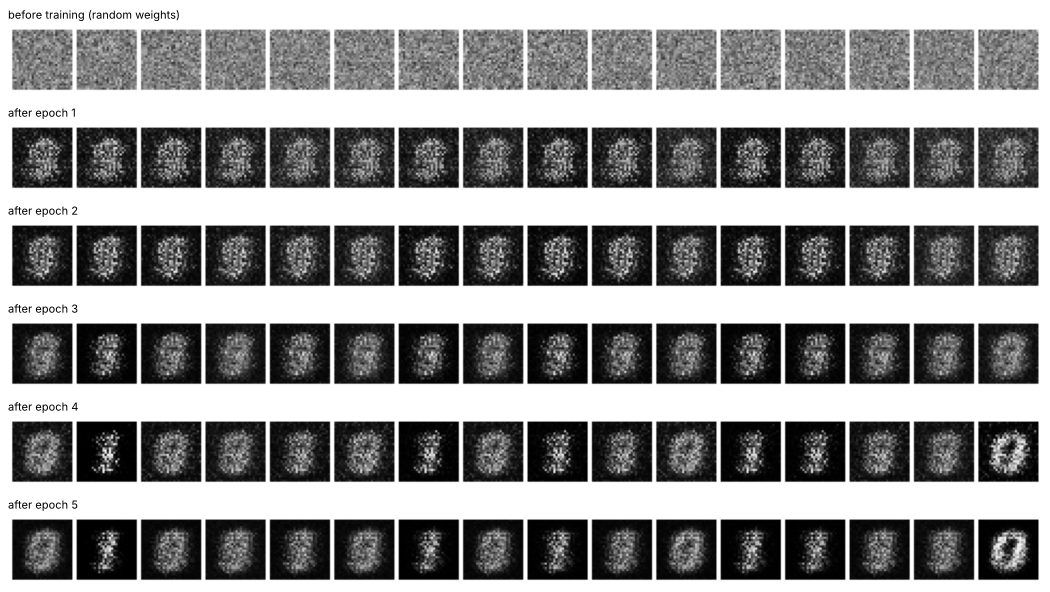

In [19]:
torch.manual_seed(42)
fixed_noise = torch.randn(16, 100)
G_A, log_A = train_gan(epochs=5, fixed_noise=fixed_noise)
runs["A: 5 epochs"] = (G_A, log_A, 100)
print(f"time: {log_A['seconds']:.0f} s")

fig, axes = plt.subplots(6, 1, figsize=(16, 7.5))
torch.manual_seed(0)
show_row(GeneratorZ()(fixed_noise).detach(), "before training (random weights)", axes[0])
for e, snap in enumerate(log_A["snapshots"]):
    show_row(snap, f"after epoch {e + 1}", axes[e + 1])
plt.tight_layout(); plt.show()

(pending TA)

### Experiment B · Smaller latent space (100 → 10)
Change 100 → 10 in all three places (`nn.Linear(100, 256)` and both `torch.randn(..., 100)`). Here that is `latent_dim=10`.

> ✏️ **Predict:** with only 10 random numbers per image, does variety drop? Does quality change?

### Experiment C · Unbalanced players (D learns 10× faster)
D gets `lr = 0.002`, G keeps 0.0002.

> ✏️ **Predict:** who wins? What happens to Loss G and to the samples?

### Experiment D · A common GAN setting: `betas=(0.5, 0.999)`
The DCGAN paper recommends Adam with lr 0.0002 and **β1 = 0.5** (less momentum than the default 0.9).

> ✏️ **Predict:** better or worse samples after 2 epochs?

All three run for the course's 2 epochs from the same seed as the baseline, so the **only** difference is the one setting.

In [20]:
G_base, log_base = train_gan()                                   # baseline = the course settings again, via the function
runs["baseline (course)"] = (G_base, log_base, 100)
G_B, log_B = train_gan(latent_dim=10)
runs["B: latent 10"] = (G_B, log_B, 10)
G_C, log_C = train_gan(lr_d=0.002)
runs["C: D lr x10"] = (G_C, log_C, 100)
G_D, log_D = train_gan(betas=(0.5, 0.999))
runs["D: betas 0.5"] = (G_D, log_D, 100)
print("seconds per 2-epoch run:", [round(l['seconds']) for l in (log_base, log_B, log_C, log_D)])

Epoch 1/2, Loss D: 0.590, Loss G: 1.404   (epoch avg D 0.700, G 1.369; mean D(x) 0.811, D(G(z)) 0.298)


Epoch 2/2, Loss D: 1.042, Loss G: 1.058   (epoch avg D 0.829, G 1.261; mean D(x) 0.714, D(G(z)) 0.302)


Epoch 1/2, Loss D: 0.933, Loss G: 1.044   (epoch avg D 0.694, G 1.374; mean D(x) 0.805, D(G(z)) 0.291)


Epoch 2/2, Loss D: 0.987, Loss G: 0.994   (epoch avg D 0.751, G 1.420; mean D(x) 0.738, D(G(z)) 0.269)


Epoch 1/2, Loss D: 0.180, Loss G: 5.775   (epoch avg D 0.358, G 4.136; mean D(x) 0.926, D(G(z)) 0.062)


Epoch 2/2, Loss D: 0.048, Loss G: 5.118   (epoch avg D 0.386, G 4.954; mean D(x) 0.910, D(G(z)) 0.056)


Epoch 1/2, Loss D: 1.052, Loss G: 0.953   (epoch avg D 0.996, G 0.916; mean D(x) 0.720, D(G(z)) 0.412)


Epoch 2/2, Loss D: 0.896, Loss G: 1.578   (epoch avg D 0.913, G 1.138; mean D(x) 0.681, D(G(z)) 0.337)
seconds per 2-epoch run: [179, 120, 102, 98]


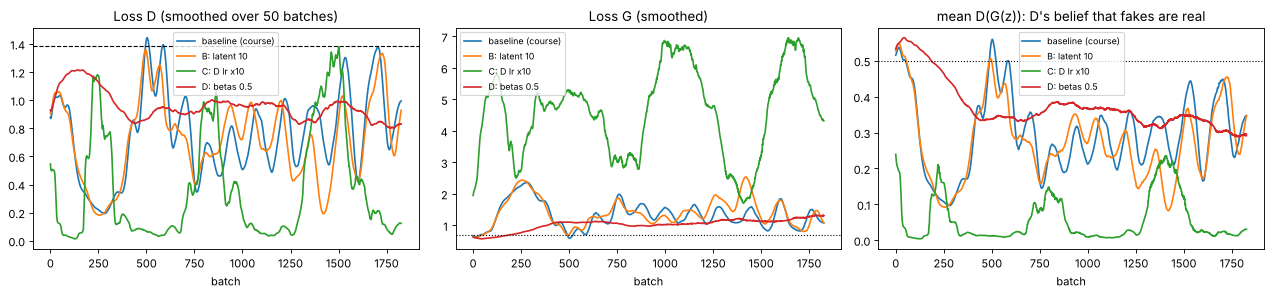

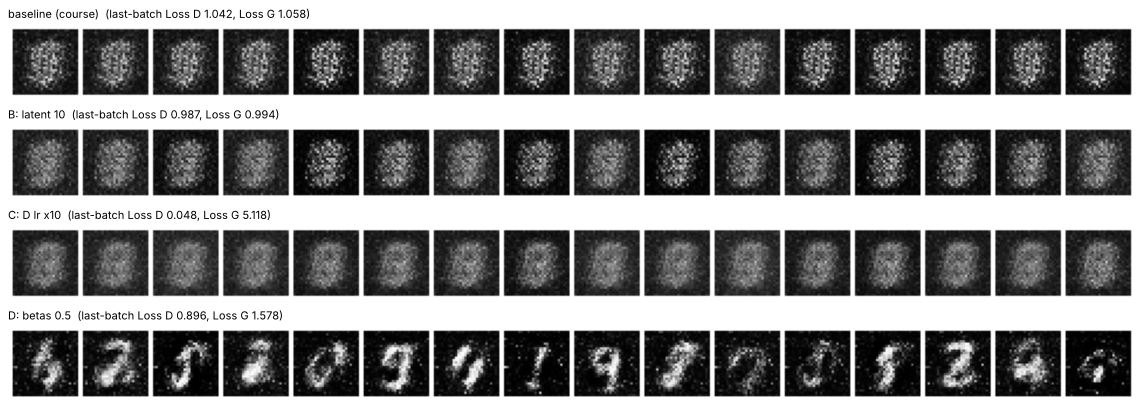

In [21]:
def smooth(x, k=50):
    return np.convolve(x, np.ones(k) / k, mode="valid")

names = ["baseline (course)", "B: latent 10", "C: D lr x10", "D: betas 0.5"]
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for name in names:
    log = runs[name][1]
    ax[0].plot(smooth(log["loss_d"]), label=name); ax[1].plot(smooth(log["loss_g"]), label=name); ax[2].plot(smooth(log["dgz"]), label=name)
ax[0].axhline(1.386, ls="--", c="k", lw=1); ax[1].axhline(0.693, ls=":", c="k", lw=1); ax[2].axhline(0.5, ls=":", c="k", lw=1)
ax[0].set_title("Loss D (smoothed over 50 batches)"); ax[1].set_title("Loss G (smoothed)"); ax[2].set_title("mean D(G(z)): D's belief that fakes are real")
for a in ax: a.set_xlabel("batch"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

torch.manual_seed(7)
z100 = torch.randn(16, 100); z10 = z100[:, :10]
fig, axes = plt.subplots(4, 1, figsize=(16, 5.2))
for a, name in zip(axes, names):
    G, log, zd = runs[name]
    show_row(G(z100 if zd == 100 else z10).detach(), f"{name}  (last-batch Loss D {log['epoch_rows'][-1][0]:.3f}, Loss G {log['epoch_rows'][-1][1]:.3f})", a)
plt.tight_layout(); plt.show()

(pending TBCD)

## Task 4 · Explore the latent space
### 4.1 Walk from one digit to another (course code, on the 2-epoch course generator)

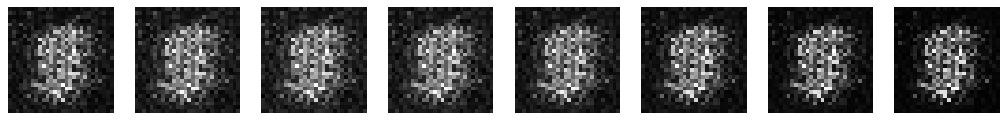

In [22]:
# new cell, after training  (course code)
torch.manual_seed(1)                                 # (added) repeatable pair of endpoints
z1 = torch.randn(1, 100)
z2 = torch.randn(1, 100)
steps = 8
fig, axes = plt.subplots(1, steps, figsize=(16, 2))
for i in range(steps):
    t = i / (steps - 1)
    z = (1 - t) * z1 + t * z2
    img = generator(z).detach()
    axes[i].imshow(img[0][0], cmap='gray')
    axes[i].axis('off')
plt.show()

`t` goes 0 → 1 in 8 steps; `z = (1 − t)·z1 + t·z2` is a straight line in latent space from z1 to z2. If G has learnt a **smooth** map, nearby z give similar images, so the picture should **morph** rather than jump.

To answer the questions properly we need to know *which digit* each image shows. A person can count, but a quick classifier is faster and fairer. We use the same tiny digit classifier as the Class 2–3 notebook: `Flatten → Linear(784, 256) → ReLU → Linear(256, 10)`, trained for one epoch on the real labelled digits. It is a **measuring tool**, not part of the GAN.

In [23]:
torch.manual_seed(0)
classifier = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 10))
opt_c = optim.Adam(classifier.parameters(), lr=1e-3)
for x, y in train_loader:                       # one epoch
    opt_c.zero_grad(); nn.functional.cross_entropy(classifier(x), y).backward(); opt_c.step()
test_data = datasets.MNIST(root='./data', train=False, transform=transform, download=True)
with torch.no_grad():
    xt = torch.stack([test_data[i][0] for i in range(len(test_data))]); yt = test_data.targets
    acc = (classifier(xt).argmax(1) == yt).float().mean().item()
print(f"digit classifier accuracy on the 10,000 real test digits: {acc:.1%}")

def classify(images):
    with torch.no_grad():
        probs = torch.softmax(classifier(images), 1)
    return probs.argmax(1), probs.max(1).values     # predicted digit and how sure it is

digit classifier accuracy on the 10,000 real test digits: 93.8%


course G, 2 epochs, pair 1: classifier reads [8, 8, 8, 8, 8, 8, 8, 8]
course G, 2 epochs, pair 2: classifier reads [8, 8, 8, 8, 8, 8, 8, 8]
course G, 2 epochs, pair 3: classifier reads [8, 8, 8, 8, 8, 8, 8, 8]


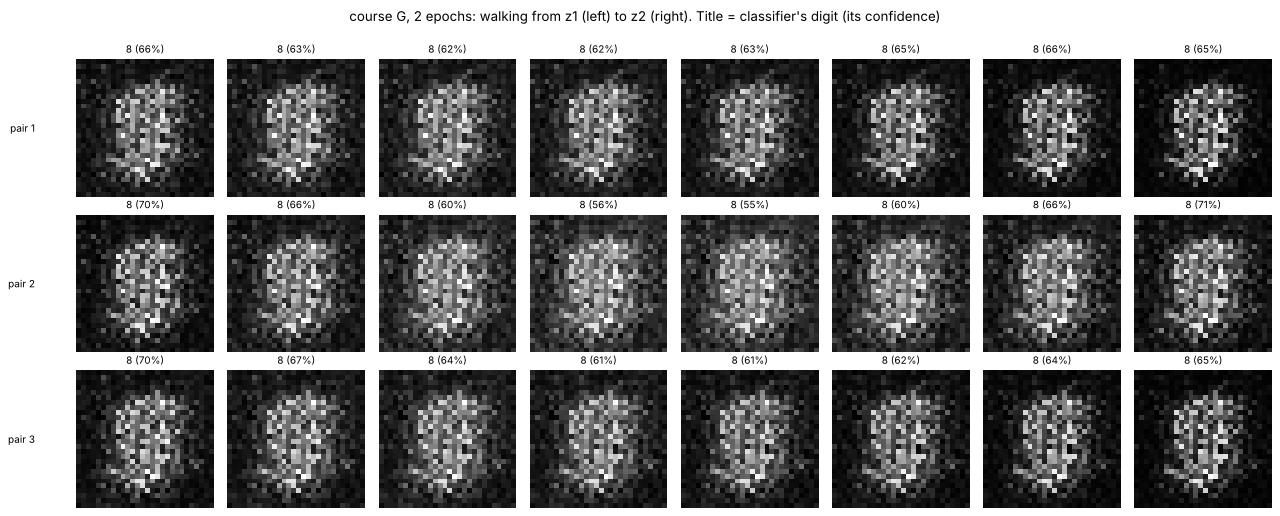

Experiment A G, 5 epochs, pair 1: classifier reads [8, 8, 8, 8, 8, 8, 8, 8]
Experiment A G, 5 epochs, pair 2: classifier reads [8, 8, 8, 8, 0, 0, 0, 0]
Experiment A G, 5 epochs, pair 3: classifier reads [8, 8, 8, 8, 8, 8, 8, 8]


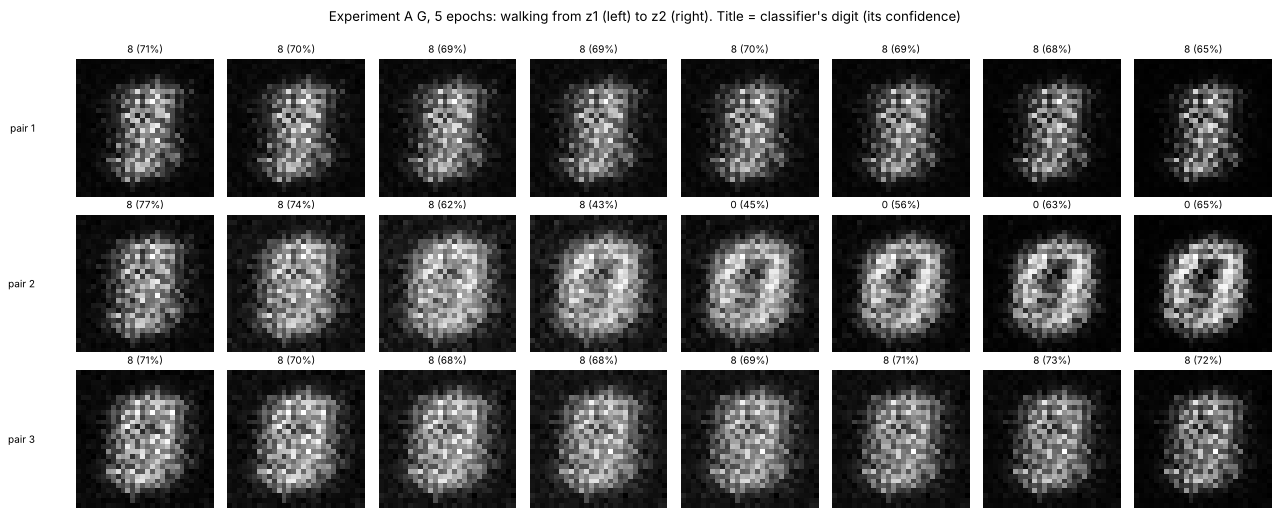

In [24]:
def interpolate(G, z1, z2, steps=8, ax_row=None, title=""):
    ts = torch.linspace(0, 1, steps).view(-1, 1)
    imgs = G((1 - ts) * z1 + ts * z2).detach()
    digit, conf = classify(imgs)
    for i in range(steps):
        ax_row[i].imshow(imgs[i][0], cmap='gray'); ax_row[i].axis('off')
        ax_row[i].set_title(f"{digit[i].item()} ({conf[i]:.0%})", fontsize=9)
    ax_row[0].text(-0.3, 0.5, title, transform=ax_row[0].transAxes, ha="right", va="center", fontsize=9)
    return digit.tolist()

pairs = []
for s in [1, 2, 3]:                       # "Run it 3 times"
    torch.manual_seed(s); pairs.append((torch.randn(1, 100), torch.randn(1, 100)))
for G, gname in [(generator, "course G, 2 epochs"), (G_A, "Experiment A G, 5 epochs")]:
    fig, axes = plt.subplots(3, 8, figsize=(16, 6.4))
    for r, (za, zb) in enumerate(pairs):
        d = interpolate(G, za, zb, ax_row=axes[r], title=f"pair {r + 1}")
        print(f"{gname}, pair {r + 1}: classifier reads", d)
    plt.suptitle(f"{gname}: walking from z1 (left) to z2 (right). Title = classifier's digit (its confidence)", y=1.0)
    plt.tight_layout(); plt.show()

(pending TINTERP)

### 4.2 Generate 64 samples and count the digits: any mode collapse?

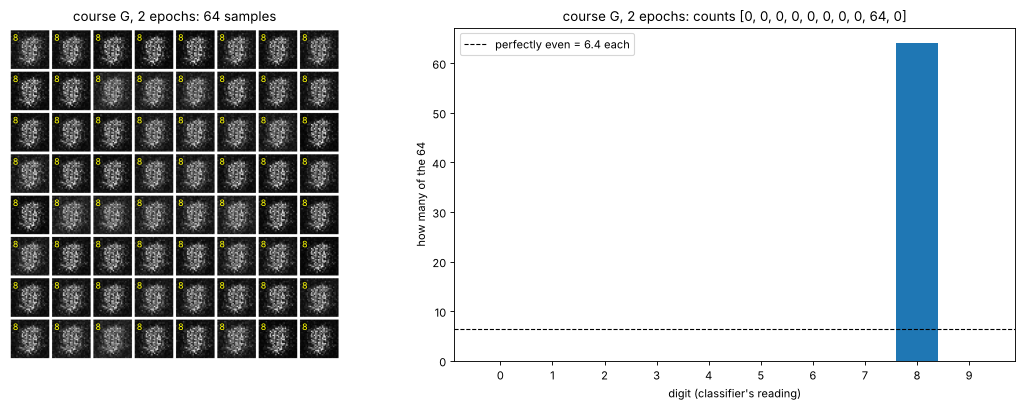

course G, 2 epochs: digits present = 1 of 10, most common = 8 (64 of 64), samples the classifier is >90% sure about: 0 of 64


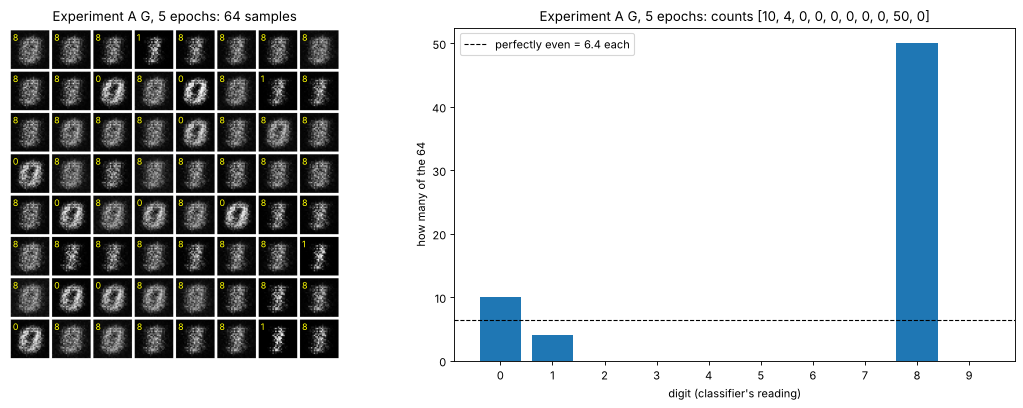

Experiment A G, 5 epochs: digits present = 3 of 10, most common = 8 (50 of 64), samples the classifier is >90% sure about: 0 of 64


In [25]:
torch.manual_seed(2024)
z64 = torch.randn(64, 100)
for G, gname in [(generator, "course G, 2 epochs"), (G_A, "Experiment A G, 5 epochs")]:
    imgs = G(z64).detach()
    digit, conf = classify(imgs)
    fig, ax = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1, 1.1]})
    ax[0].imshow(make_grid(imgs, nrow=8, normalize=True, value_range=(-1, 1), pad_value=1).permute(1, 2, 0)); ax[0].axis("off")
    for k in range(64):                      # write the classifier's answer in the corner of each cell
        ax[0].text((k % 8) * 30 + 3, (k // 8) * 30 + 9, str(digit[k].item()), color="yellow", fontsize=8)
    counts = torch.bincount(digit, minlength=10)
    ax[1].bar(range(10), counts); ax[1].set_xticks(range(10)); ax[1].set_xlabel("digit (classifier's reading)"); ax[1].set_ylabel("how many of the 64")
    ax[1].axhline(6.4, ls="--", c="k", lw=1, label="perfectly even = 6.4 each"); ax[1].legend()
    ax[0].set_title(f"{gname}: 64 samples"); ax[1].set_title(f"{gname}: counts {counts.tolist()}")
    plt.tight_layout(); plt.show()
    print(f"{gname}: digits present = {(counts > 0).sum().item()} of 10, most common = {counts.argmax().item()} ({counts.max().item()} of 64), "
          f"samples the classifier is >90% sure about: {(conf > 0.9).sum().item()} of 64")

(pending TCOUNT)

### 4.3 Bonus: variety and "digit-likeness" of every run, measured on 1,000 samples
Sixty-four samples is a small count. Here every generator from Tasks 1 and 3 makes **1,000** digits; we count how many of each digit the classifier sees, and how many samples it is more than 90% sure about (a rough proxy for "looks like a clear digit"; a classifier can be confidently wrong on junk, so always check the pictures too).

In [26]:
runs_all = {"Task 1 (course cell)": (generator, None, 100)}
runs_all.update(runs)
torch.manual_seed(99)
z1000 = torch.randn(1000, 100)
print(f"{'run':22s} {'digit counts 0..9':48s} {'present':>7s} {'largest':>7s} {'>90% sure':>9s}")
hist = {}
for name, (G, log, zd) in runs_all.items():
    digit, conf = classify(G(z1000[:, :zd]).detach())
    counts = torch.bincount(digit, minlength=10)
    hist[name] = counts
    print(f"{name:22s} {str(counts.tolist()):48s} {(counts >= 10).sum().item():7d} {counts.max().item():7d} {(conf > 0.9).float().mean().item():9.1%}")
print("(present = digits with at least 10 of the 1,000 samples; a perfectly even generator gives 100 each)")

run                    digit counts 0..9                                present largest >90% sure
Task 1 (course cell)   [0, 0, 0, 0, 0, 0, 0, 0, 1000, 0]                      1    1000      0.0%
A: 5 epochs            [173, 118, 0, 0, 0, 0, 0, 0, 709, 0]                   3     709      0.1%
baseline (course)      [0, 0, 0, 0, 0, 0, 0, 0, 1000, 0]                      1    1000      0.0%
B: latent 10           [0, 0, 0, 0, 0, 0, 0, 0, 1000, 0]                      1    1000      0.0%
C: D lr x10            [0, 0, 0, 0, 0, 0, 0, 0, 1000, 0]                      1    1000      0.0%
D: betas 0.5           [42, 123, 90, 166, 132, 76, 136, 59, 87, 89]          10     166     19.4%
(present = digits with at least 10 of the 1,000 samples; a perfectly even generator gives 100 each)


(pending TALL)

---
## Exit ticket (from the last slide) with answers

1. **Write the full form of GAN. Explain "adversarial" in one sentence.** Generative Adversarial Network(s). Two networks with **opposite goals on the same score**: D wants fakes scored "fake", G wants them scored "real".
2. **For a generated image, D(G(z)) = 0.3. Which way does D want it to move? Which way does G?** D wants it to go **down to 0**; G wants it to go **up to 1**.
3. **In the notebook, what does `fake.detach()` do in the discriminator step?** It stops gradients flowing back into G, so only D learns in that step (we proved it above: G's gradient was `None`).
4. **Muddiest point:** yours to write. A common one is "why `labels_real` for fakes?": see Task 2c and the saturating vs non-saturating plot.

## Viva practice: 14 questions with short answers

1. **Generative vs discriminative model?** A discriminative model learns p(label | image) and outputs a label; a generative model learns to sample like p(image) and outputs new data.
2. **What goes in and out of G and D here?** G: 100 noise numbers → a 1×28×28 image (100 → 256 → 784, Tanh). D: an image → one probability P(real) (784 → 256 → 1, Sigmoid).
3. **Why Tanh at the end of G?** Real pixels were normalised to −1…+1; Tanh gives fakes the same range, so D cannot spot fakes by range alone.
4. **Why LeakyReLU(0.2) in D?** G learns only through gradients flowing back through D; LeakyReLU never fully blocks them for negative inputs.
5. **Write the minimax objective. Who pushes which way?** min_G max_D E[log D(x)] + E[log(1 − D(G(z)))]. D pushes V up, G pushes it down; G cannot affect the first term.
6. **How does `loss_d` relate to V?** BCE is the negative log, so `loss_d = −[log D(x) + log(1 − D(G(z)))]`; minimising `loss_d` = maximising V.
7. **What is the optimal D for a fixed G, and what happens when G is perfect?** D*(x) = p_data(x) / (p_data(x) + p_g(x)); if p_g = p_data, D* = ½ everywhere: a Nash equilibrium.
8. **Where do 1.386 and 0.693 come from?** If D outputs 0.5 everywhere, each BCE term is −ln 0.5 = 0.693; `loss_d` has two terms (1.386), `loss_g` one (0.693).
9. **Why does G's loss use target 1 (non-saturating loss)?** log(1 − D(G(z))) is flat when D(G(z)) ≈ 0, so G gets almost no gradient early; −log D(G(z)) is steep there (about 1000× stronger at 0.001 in our check). Same goal, better gradients.
10. **Why two optimizers?** Each holds only its own network's weights, so each `step()` updates one player while the other stays fixed.
11. **Why `real.size(0)` instead of 64?** The last batch of each epoch has only 32 images (60,000 = 937 × 64 + 32).
12. **Do GAN losses tell you image quality?** No. Each loss is measured against a moving opponent; always look at samples (and, better, count variety).
13. **What is mode collapse and how would you detect it here?** G produces only one or a few kinds of output (e.g. mostly one digit). Look at a grid of 64+ samples and count digits with a classifier, as in Task 4.
14. **Which network is kept after training, and why do we need the other?** G is kept (it makes images). D is the coach: it learns from real data what digits look like and passes that knowledge to G through its gradients; there is no formula to score "looks like a digit" otherwise.

**Next:** notebook `02_gan_training_dynamics.ipynb` (Classes 2 & 3: why this game is hard to win) and `03_dcgan_and_conditional_gan.ipynb` (the DCGAN mini-project and the conditional-GAN assignment from this notebook's last cells).

*Source: code reconstructed from the course guide "GAN Class 1 Notebook Explained" (CV-Week4-Lecture1.ipynb) and the GAN Class 1 slides; reference: Goodfellow et al., Generative Adversarial Nets (2014).*